# A ray traced KrF illuminator for the Caldwell lens

The projection lens of notebooks 19, 33 and 41 (Caldwell, NA 0.56, 4x, KrF)
needs an illuminator: it has to fill the pupil of the lens with the chosen
setting (conventional $\sigma$ up to about 0.8, annular), illuminate the
field uniformly and send the light along the chief rays of the lens
(telecentricity). There is no published KrF illuminator with lens data from
the laser to the reticle, so this one is put together from two Zeiss
patents of the 1990s and two invented parts, following the architecture of
those patents (`pyoptics.litho.illuminator.KrFIlluminator`):

| # | part | source | model |
|---|------|--------|-------|
| 1 | secondary source (laser + beam shaper + diffuser) | invented | disk of 1 mm radius, uniform in the direction sines up to 0.185 |
| 2 | zoom-axicon objective | US 5,675,401, Table 2 (i-line, quartz + FK5) | ray traced, re-glassed to fused silica at 248 nm (`raytrace.zeiss_zoom_axicon()`) |
| 3 | diffuser in the pupil plane 30 ("component 8" of US 5,675,401) | invented | adds directions within ±0.123 (tangent, square): fills the rod entrance |
| 4 | coupling lens ("objective 4") | invented | ideal lens, f = 60 mm, pupil plane 30 → rod entrance |
| 5 | glass rod with the masking blades at its exit | invented | fused silica, 14.8 × 14.8 × 500 mm, traced exactly by unfolding the reflections |
| 6 | REMA objective | US 5,982,558, Table 1 (248.38 nm, fused silica) | ray traced (`raytrace.zeiss_krf_rema()`) |

The REMA images the rod exit onto the reticle at −4.457x: the 14.8 mm rod
becomes a 66 mm square on the reticle, a 16.5 mm square on the wafer, which
just fits into Caldwell's 23.4 mm image field circle. Its image side NA of
about 0.135 against Caldwell's reticle side NA of 0.56/4 = 0.14 allows
$\sigma$ up to about 0.96.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

from pyoptics.raytrace import (Rays, caldwell_krf_lens, zeiss_krf_rema, zeiss_zoom_axicon,
                               fused_silica)
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, metrics
from pyoptics.litho.illuminator import KrFIlluminator

plt.rcParams.update({"figure.dpi": 80, "font.size": 11})
t_start = time.time()

caldwell = caldwell_krf_lens()
rema = zeiss_krf_rema()
p = rema.paraxial()
print(f"REMA: magnification {p.magnification:.4f}, object to reticle "
      f"{rema.image_z + rema.object_distance:.2f} mm, stop semi diameter "
      f"{rema.surfaces[12].semi_diameter:.2f} mm (object side NA 0.6)")
print(f"Caldwell: reticle side NA {0.56/4:.3f}, object field radius {caldwell.max_field} mm")

REMA: magnification -4.4570, object to reticle 1200.00 mm, stop semi diameter 72.20 mm (object side NA 0.6)
Caldwell: reticle side NA 0.140, object field radius 46.8 mm


## The parts

The zoom-axicon of US 5,675,401 takes the light of the secondary source
(plane 130) to the pupil intermediate plane 30. Its directions become
positions there: the size of the illuminated disk is the $\sigma$ of the
illuminator. Two elements move: the second element (2121/2120) and the zoom
lens (2410/2420); both far from the axicons give the small disk, both close
to them the large one (about three times larger). Pulling the two axicons
(cones of 62°, which are in contact for conventional settings) apart shifts
the light outwards into a ring.

The patent's design is for the mercury i-line (quartz and Schott FK5). For
248 nm all elements are fused silica, and the radii of each element are
scaled by $(n_{248}-1)/(n_{365}-1)$ so that it keeps its power. FK5 at
365 nm (1.504) and fused silica at 248 nm (1.508) are almost the same, so
the change is small except for the first (quartz) meniscus.

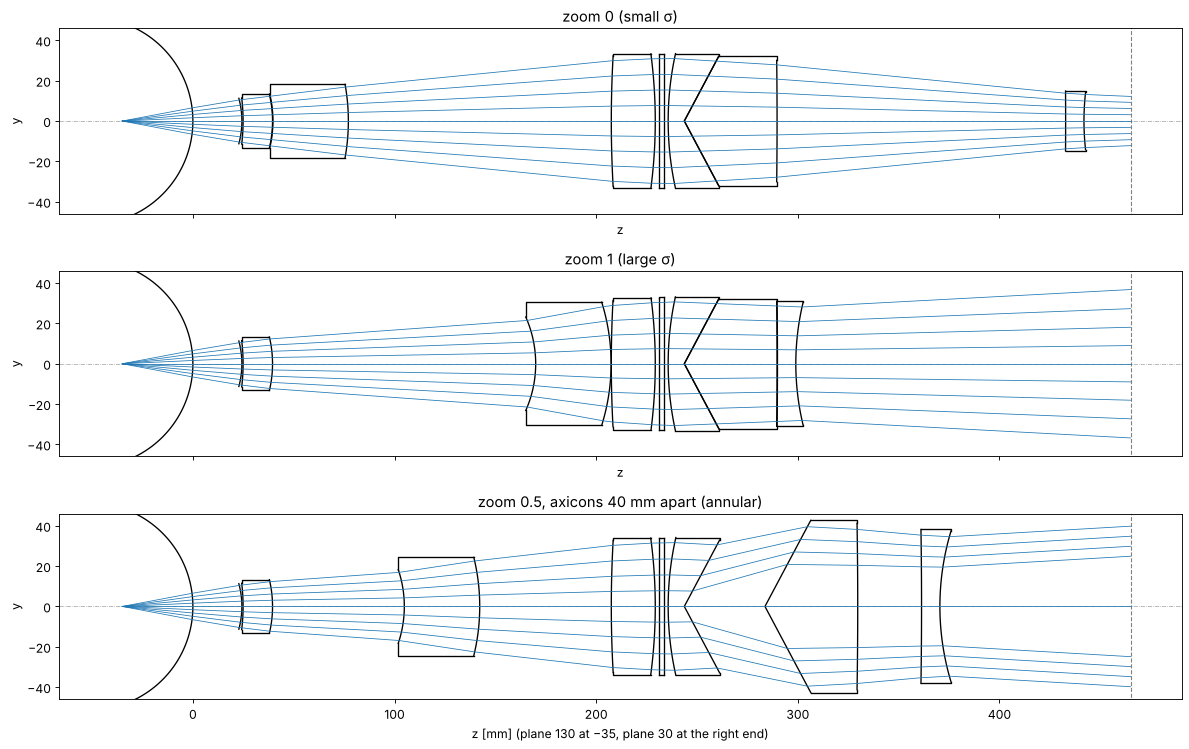

In [2]:
def source_fan(n=9, na=0.185, heights=(0.0,)):
    s = np.linspace(-na, na, n)
    P, d = [], []
    for h in heights:
        for si in s:
            P.append([0.0, h, -35.0]); d.append([0.0, si, np.sqrt(1 - si**2)])
    return Rays(np.array(P), np.array(d), np.zeros(len(P)))


def draw_fan(system, rays, ax, title):
    b = system.trace(rays, clip=False)
    s = system.copy()
    for i, surf in enumerate(s.surfaces):
        if surf.semi_diameter is None:
            surf.semi_diameter = 1.08*np.nanmax(np.abs(b.points[i + 1][:, 1]))
    s.draw(ax=ax, fields=[0.0], n_rays=3, lw=0)
    ax.plot(b.points[:, :, 2], b.points[:, :, 1], color="C0", lw=0.7)
    ax.set_title(title)


fig, axes = plt.subplots(3, 1, figsize=(15, 9.5), sharex=True)
for ax, (zoom, gap, title) in zip(axes, [(0.0, 0.0, "zoom 0 (small σ)"),
                                         (1.0, 0.0, "zoom 1 (large σ)"),
                                         (0.5, 40.0, "zoom 0.5, axicons 40 mm apart (annular)")]):
    draw_fan(zeiss_zoom_axicon(zoom, gap), source_fan(), ax, title)
axes[-1].set_xlabel("z [mm] (plane 130 at −35, plane 30 at the right end)")
plt.tight_layout()

The REMA objective (US 5,982,558) images the rod exit (left, where the
masking blades sit) onto the reticle (right). Group 100 is corrected as an
objective with its object at infinity up to the diaphragm plane 14, group
300 adapts the chief rays to the entrance pupil of the projection lens.
The patent's deflection mirror at plane 24 is unfolded here.

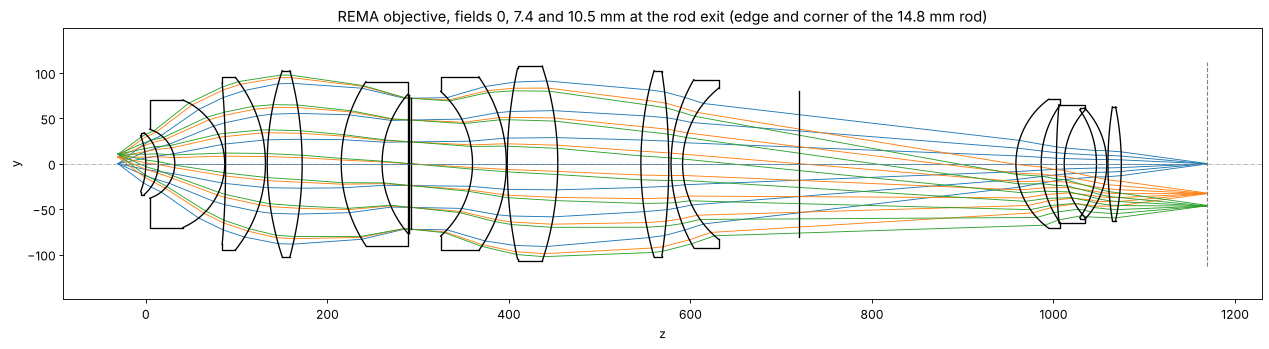

In [3]:
fig, ax = plt.subplots(figsize=(16, 4.5))
rema.draw(ax=ax, fields=[0.0, 7.4, 10.5], n_rays=7)
ax.set_title("REMA objective, fields 0, 7.4 and 10.5 mm at the rod exit (edge and corner of the 14.8 mm rod)")
plt.tight_layout()

### A misprint in the REMA table

The patent lists for every surface the sines of the angles of incidence (in
air) of the marginal ray (RD), the upper and lower coma rays (O1, U1) and the
chief ray (H1). With the printed table the trace agrees with them only up to
surface 19; behind it the angles drift, the paraxial image lies 19 mm behind
the reticle plane and the magnification is −4.25 instead of −4.44. The
thickness behind surface 19 (printed 36.53 mm) is the culprit: fitting it to
the 116 listed sines gives about 90 mm, and 91.56 mm makes the length from
object to reticle exactly the 1200 mm stated in the text and puts the best
focus at the printed 94.55 mm. With it 115 of the 116 sines agree to the
rounding of the table, within 0.01 (the one exception, U1 at surface 32,
differs in sign only: a second misprint).

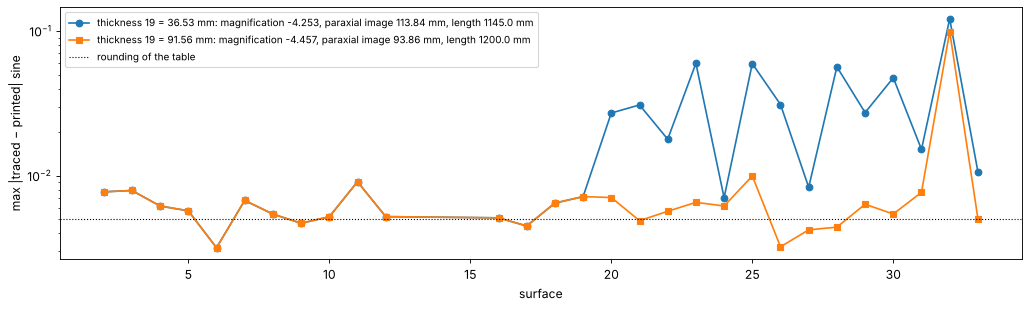

In [4]:
TABLE = {2: (.38, .47, .11, -.29), 3: (-.15, .07, .28, .38), 4: (-.43, -.19, .28, .65),
         5: (-.43, -.29, .16, .56), 6: (.37, .39, .03, -.36), 7: (-.35, -.25, .11, .45),
         8: (.45, .46, .01, -.44), 9: (-.29, -.20, .10, .38), 10: (.44, .48, .04, -.40),
         11: (.62, .67, .05, -.56), 12: (.01, .09, .08, .06), 16: (-.66, -.62, .03, .69),
         17: (-.38, -.34, .03, .41), 18: (.32, .41, .10, -.24), 19: (-.34, -.33, .02, .36),
         20: (.13, .22, .10, -.04), 21: (-.37, -.38, -.00, .36), 22: (.14, .23, .11, -.05),
         23: (.52, .70, .21, -.34), 24: (-.12, -.04, .05, .17), 25: (.17, .69, .47, .27),
         26: (.02, .32, .29, .27), 27: (-.15, -.14, .03, .19), 28: (.11, .69, .54, .41),
         29: (-.22, -.40, -.18, .04), 30: (-.25, -.59, -.33, -.07), 31: (-.06, .17, .22, .28),
         32: (-.18, -.30, -.13, -.05), 33: (-.13, -.13, .00, .14)}


def sines(system, h=-9.56):
    s = np.array([.6, .6, 0, -.6]); y = np.array([0, h, h, h])
    P = np.stack([0*y, y, np.full(4, -system.object_distance)], axis=-1)
    b = system.trace(Rays(P, np.stack([0*s, s, np.sqrt(1 - s**2)], axis=-1), np.zeros(4)), clip=False)
    n, out = system.n, {}
    for i, surf in enumerate(system.surfaces):
        Q = b.points[i + 1] - [0, 0, system.vertex_z[i]]
        d = b.directions[i] if n[i] < 1.2 else b.directions[i + 1]
        c = np.cross(d, surf.normal(Q))
        out[int(surf.label)] = np.sign(c[:, 0])*np.linalg.norm(c, axis=1)
    out[33] = b.directions[-1][:, 1]
    return out


fig, ax = plt.subplots(figsize=(13, 4))
for t19, style in [(36.53, "o-"), (91.56, "s-")]:
    sys_ = zeiss_krf_rema(thickness_19=t19)
    s = sines(sys_)
    err = [np.abs(s[k] - np.array(v)).max() for k, v in TABLE.items()]
    p = sys_.paraxial()
    ax.plot(list(TABLE), err, style, label=f"thickness 19 = {t19} mm: magnification {p.magnification:.3f}, "
            f"paraxial image {p.image_distance:.2f} mm, length {sys_.image_z + sys_.object_distance:.1f} mm")
ax.axhline(0.005, color="k", ls=":", lw=1, label="rounding of the table")
ax.set_xlabel("surface"); ax.set_ylabel("max |traced − printed| sine"); ax.set_yscale("log")
ax.legend(fontsize=9); plt.tight_layout()

## Pupil fills

`KrFIlluminator` traces 400 000 rays from the source to the reticle. The
pupil fill at a field point is the histogram of the ray directions in
$\sigma$ coordinates (reticle side direction sines over the reticle side NA
0.14 of the lens) of the rays that land within ±1 mm (wafer scale) of the
point. `for_sigma()` sets the zoom (and for a ring the axicon gap) for the
radii that hold 5 % and 95 % of the light.

In [5]:
settings = [("zoom 0", dict(zoom=0.0)), ("zoom 0.5", dict(zoom=0.5)), ("σ 0.8", (0.8, None)),
            ("ring 0.5/0.8", (0.8, 0.5)), ("ring 0.6/0.8", (0.8, 0.6)), ("ring 0.7/0.85", (0.85, 0.7))]
illuminators = {}
for name, s in settings:
    t = time.time()
    if isinstance(s, dict):
        il = KrFIlluminator(**s)
    else:
        il = KrFIlluminator().for_sigma(*s)
    illuminators[name] = il
    s_in, s_out = il.sigma()
    print(f"{name:14s} zoom {np.round(il.zoom, 3)!s:6s} axicon gap {il.axicon_gap:5.1f} mm:"
          f" σ_in(5%) {s_in:.3f}  σ_out(95%) {s_out:.3f}   ({time.time() - t:.1f} s)")

zoom 0         zoom 0.0    axicon gap   0.0 mm: σ_in(5%) 0.071  σ_out(95%) 0.317   (16.1 s)


zoom 0.5       zoom 0.5    axicon gap   0.0 mm: σ_in(5%) 0.134  σ_out(95%) 0.551   (12.6 s)


σ 0.8          zoom 0.96   axicon gap   0.0 mm: σ_in(5%) 0.193  σ_out(95%) 0.804   (10.3 s)


ring 0.5/0.8   zoom 0.459  axicon gap  31.8 mm: σ_in(5%) 0.504  σ_out(95%) 0.804   (16.7 s)


ring 0.6/0.8   zoom 0.234  axicon gap  48.3 mm: σ_in(5%) 0.604  σ_out(95%) 0.805   (17.6 s)


ring 0.7/0.85  zoom 0.139  axicon gap  63.7 mm: σ_in(5%) 0.704  σ_out(95%) 0.855   (18.9 s)


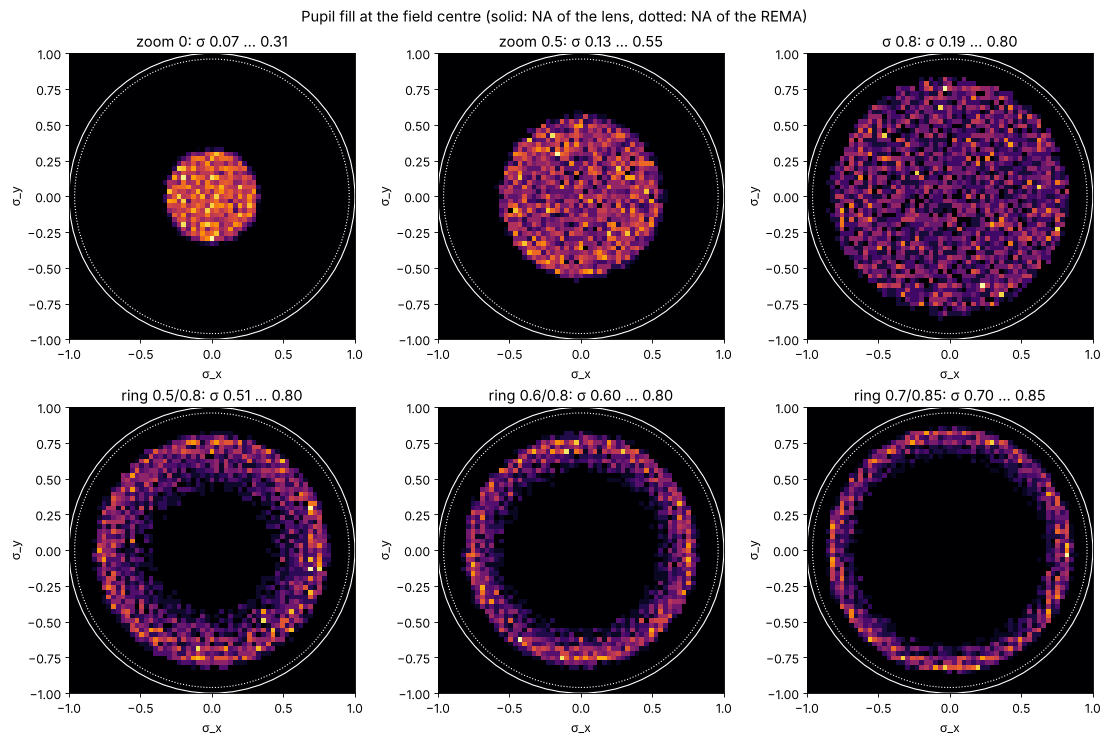

In [6]:
def fill_image(il, field=(0.0, 0.0), window=1.0, n=61):
    s = il.reticle_rays(field, window).sigma
    edges = np.linspace(-1, 1, n + 1)
    H, _, _ = np.histogram2d(s[:, 0], s[:, 1], bins=[edges, edges])
    return H.T/H.max()


fig, axes = plt.subplots(2, 3, figsize=(14, 9.4))
for ax, (name, il) in zip(axes.ravel(), illuminators.items()):
    ax.imshow(fill_image(il), extent=(-1, 1, -1, 1), origin="lower", cmap="inferno")
    for r, ls in [(1.0, "-"), (0.96, ":")]:
        ax.add_patch(Circle((0, 0), r, fill=False, color="w", ls=ls, lw=1))
    s_in, s_out = il.sigma((0.0, 0.0))
    ax.set_title(f"{name}: σ {s_in:.2f} … {s_out:.2f}")
    ax.set_xlabel("σ_x"); ax.set_ylabel("σ_y")
fig.suptitle("Pupil fill at the field centre (solid: NA of the lens, dotted: NA of the REMA)")
plt.tight_layout()

### Why the diffuser

The rod is a kaleidoscope: a point of its exit face sees the entrance face
mirrored over and over, a grid of virtual entrance faces $w$ = 14.8 mm
apart at the distance $L$ = 500 mm, i.e. directions $w/L$ apart in the
glass ($\Delta\sigma \approx 0.07$ at the reticle). If only a small spot of
the entrance is lit, the pupil fill is a grid of separate spots. The
diffuser in plane 30 spreads the light over the whole entrance face; the
images then tile the pupil without gaps. It costs the light that overfills
the entrance (about 15 %).

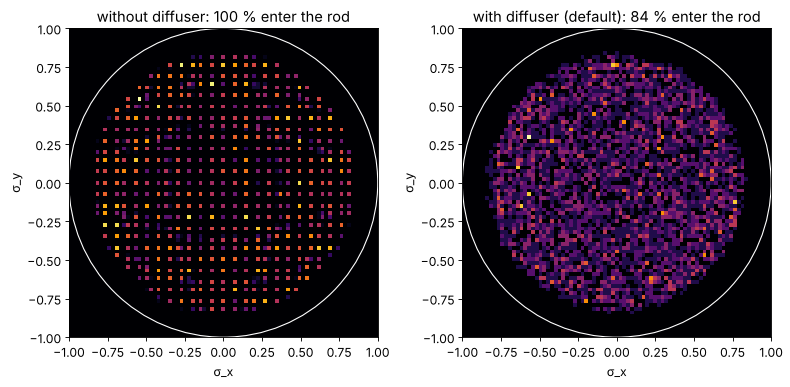

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, (title, il) in zip(axes, [("without diffuser", KrFIlluminator(zoom=1.0, diffuser_angle=0.0)),
                                  ("with diffuser (default)", illuminators["σ 0.8"])]):
    ax.imshow(fill_image(il, n=81), extent=(-1, 1, -1, 1), origin="lower", cmap="inferno")
    ax.add_patch(Circle((0, 0), 1.0, fill=False, color="w", lw=1))
    ax.set_title(f"{title}: {100*il.rod_exit_rays()[2]:.0f} % enter the rod")
    ax.set_xlabel("σ_x"); ax.set_ylabel("σ_y")
plt.tight_layout()

The radial profiles show what the patents' figures show for the lamp: the
fill is not a top hat. The zoom-axicon maps directions onto pupil radii with
some distortion, so the radiance is not flat, the edge has a finite width
(the 1 mm source blurs it), and the rings have soft inner flanks.

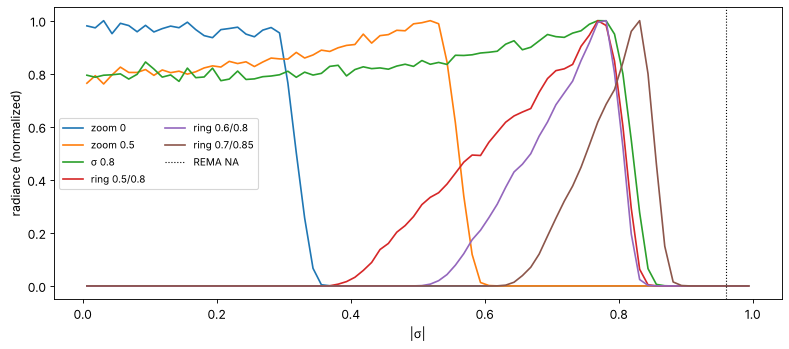

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 81)
rc = (bins[1:] + bins[:-1])/2
for name, il in illuminators.items():
    s = np.hypot(*il.reticle_rays().sigma.T)
    H, _ = np.histogram(s, bins)
    radiance = H/(2*np.pi*rc*np.diff(bins))
    ax.plot(rc, radiance/radiance.max(), label=name)
ax.axvline(0.96, color="k", ls=":", lw=1, label="REMA NA")
ax.set_xlabel("|σ|"); ax.set_ylabel("radiance (normalized)"); ax.legend(ncol=2, fontsize=9)
plt.tight_layout()

## Across the field

The rod mixes the light: every point of its exit sees the light of the
whole entrance, mirrored a few times. The field is therefore uniform (the
rest is shot noise of the ray count), the fill is symmetric and nearly the
same everywhere. What changes over the field is the REMA's imaging:
distortion and the direction of its chief rays.

rays per cell 2762: shot noise ±1.9 %, non uniformity (max − min)/(max + min) = 4.8 %


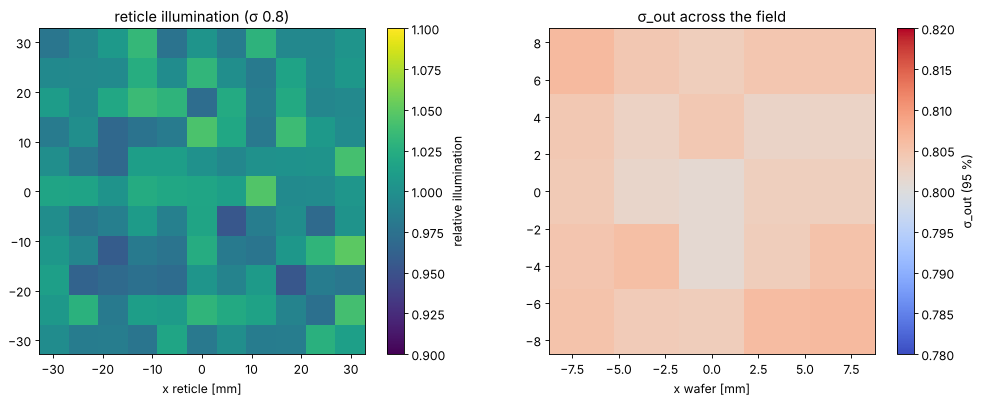

In [9]:
il = illuminators["σ 0.8"]
H, nu = il.uniformity(n_bins=11)
n_mean = H.mean()
print(f"rays per cell {n_mean:.0f}: shot noise ±{100/np.sqrt(n_mean):.1f} %, "
      f"non uniformity (max − min)/(max + min) = {100*nu:.1f} %")

xs = np.linspace(-7.0, 7.0, 5)
sig = np.array([[il.sigma((x, y), window=1.2)[1] for x in xs] for y in xs])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
half = 0.995*il.rod_width/2*abs(il.rema_magnification)
im = axes[0].imshow(H.T/n_mean, extent=(-half, half, -half, half), origin="lower", cmap="viridis",
                    vmin=0.9, vmax=1.1)
plt.colorbar(im, ax=axes[0], label="relative illumination")
axes[0].set_title("reticle illumination (σ 0.8)"); axes[0].set_xlabel("x reticle [mm]")
im = axes[1].imshow(sig, extent=(-8.75, 8.75, -8.75, 8.75), origin="lower", cmap="coolwarm",
                    vmin=0.78, vmax=0.82)
plt.colorbar(im, ax=axes[1], label="σ_out (95 %)")
axes[1].set_title("σ_out across the field"); axes[1].set_xlabel("x wafer [mm]")
plt.tight_layout()

### Telecentricity against Caldwell

The light at a reticle point should arrive centred on the chief ray of the
projection lens there; otherwise the fill is decentred in the lens pupil and
images shift through focus (notebook 41). `telecentricity()` gives the
centroid of the illumination directions minus Caldwell's object side chief
ray. The REMA patent asks for less than 3 mrad.

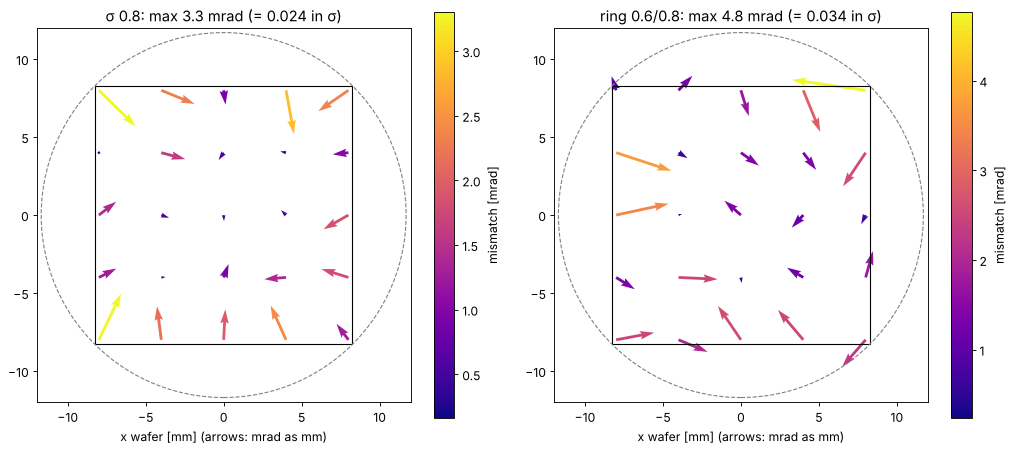

In [10]:
xs = np.linspace(-8.0, 8.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, name in zip(axes, ["σ 0.8", "ring 0.6/0.8"]):
    il = illuminators[name]
    X, Y = np.meshgrid(xs, xs)
    T = np.array([[il.telecentricity(caldwell, (x, y), window=1.2) for x in xs] for y in xs])*1e3
    q = ax.quiver(X, Y, T[..., 0], T[..., 1], np.hypot(T[..., 0], T[..., 1]), cmap="plasma",
                  angles="xy", scale_units="xy", scale=1.0)
    plt.colorbar(q, ax=ax, label="mismatch [mrad]")
    ax.add_patch(Rectangle((-8.25, -8.25), 16.5, 16.5, fill=False, color="k", lw=1))
    ax.add_patch(Circle((0, 0), 11.7, fill=False, color="0.5", ls="--"))
    ax.set_aspect("equal"); ax.set_xlim(-12, 12); ax.set_ylim(-12, 12)
    ax.set_title(f"{name}: max {np.hypot(T[..., 0], T[..., 1]).max():.1f} mrad "
                 f"(= {np.hypot(T[..., 0], T[..., 1]).max()*1e-3/0.14:.3f} in σ)")
    ax.set_xlabel("x wafer [mm] (arrows: mrad as mm)")
plt.tight_layout()

## In the lithography simulation

`pupil_fill()` returns an `Illumination` that goes straight into
`LithoSimulation`. Compared with the ideal top hat of the same σ (95 %
radius), the real fill has a weaker centre and a soft edge. The CDs of
dense and isolated lines through focus show how much that matters for
Caldwell's lens (ideal, aberration free projector, NA 0.56, binary mask,
threshold 0.3).

total run time 170 s


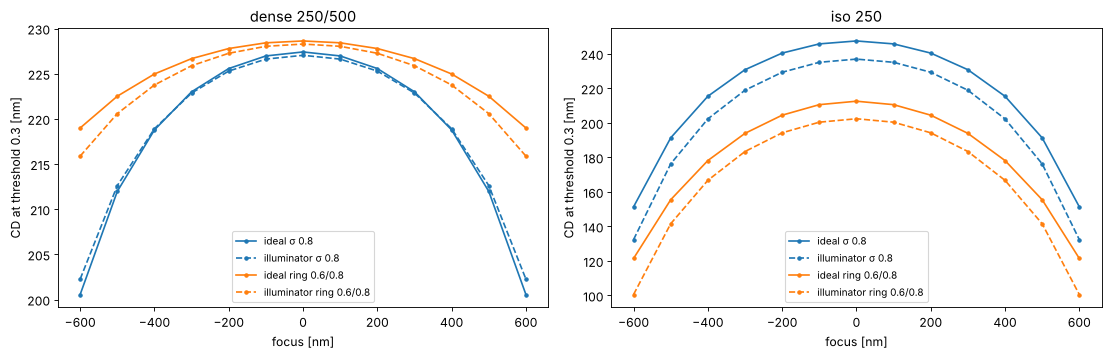

In [11]:
WL = 248.3
projector = Projector(0.56, WL, magnification=4.0)
x = np.linspace(-600, 600, 1201)
layouts = {"dense 250/500": MaskLayout.lines_spaces(500.0, 250.0),
           "iso 250": MaskLayout.iso_line(250.0, 3000.0)}
foci = np.linspace(-600, 600, 13)
sources = {"ideal σ 0.8": Illumination.conventional(0.8, n_samples=31),
           "illuminator σ 0.8": illuminators["σ 0.8"].pupil_fill(n_samples=31),
           "ideal ring 0.6/0.8": Illumination.annular(0.8, 0.6, n_samples=31),
           "illuminator ring 0.6/0.8": illuminators["ring 0.6/0.8"].pupil_fill(n_samples=31)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (lname, layout) in zip(axes, layouts.items()):
    for k, (sname, src) in enumerate(sources.items()):
        sim = LithoSimulation(layout, ThinMask.binary(), src, projector)
        cd = [metrics.threshold_cd(x, sim.image(x, focus=f), 0.3) for f in foci]
        ax.plot(foci, cd, ("-" if "ideal" in sname else "--") + "o", color=f"C{k//2}", ms=3,
                label=sname)
    ax.set_title(lname); ax.set_xlabel("focus [nm]"); ax.set_ylabel("CD at threshold 0.3 [nm]")
    ax.legend(fontsize=9)
plt.tight_layout()
print(f"total run time {time.time() - t_start:.0f} s")

## Summary

- **REMA** (US 5,982,558): all fused silica, −4.457x, NA 0.6 → 0.135. The
  printed air space behind surface 19 is a misprint; 91.56 mm reproduces the
  patent's ray angles, its 1200 mm length and its focus.
- **Zoom-axicon** (US 5,675,401, re-glassed for 248 nm): σ (95 % radius)
  from 0.32 to 0.83 with the default source, rings from narrow ones near
  the rim down to inner radii of about half the outer one; the REMA stops
  everything beyond σ 0.96.
- **Rod** (invented, 14.8 × 14.8 × 500 mm) with a diffuser that fills its
  entrance: uniform field, symmetric and gap free fill, the same σ
  everywhere in the field.
- **Against Caldwell**: the illumination centroid follows the chief rays of
  the lens to about 3 mrad (σ 0.8) and 5 mrad (ring 0.6/0.8) at the edges
  and corners of the field, which includes about 1 mrad of shot noise of
  the ray count: 0.02 to 0.03 in σ.
- The real fill differs from the ideal top hat by its soft edge and its
  uneven radial profile. Dense 250/500 lines hardly notice (CD within 1 nm
  at σ 0.8, 1 to 3 nm with the ring); the isolated 250 nm line prints
  about 10 nm narrower than with the ideal source of the same 95 % σ, for
  both settings.

Invented parts (source, diffuser, coupling lens, rod) are first order models with
values chosen to fit the two patents to Caldwell's lens; they are
parameters of `KrFIlluminator`.